# SenCLIP: prompt selection and zero-shot classification on my own images

**Idea:** SenCLIP aligns Sentinel-2 satellite images with CLIP embeddings of *ground-level* photos.
Because of this, text prompts describing a place from the ground (and from above) can be matched with satellite images.

**What this notebook does**
1. Takes my images and my own target classes (prompts written by an LLM, 50 per class, ground view and aerial view).
2. For every model, ranks the prompts with the paper's score: **w = alpha / beta**
   - alpha = average similarity of a prompt to the other prompts of its own class
   - beta = average similarity of the prompt to all prompts of all classes
   - high w = prompt represents its class well and is different from the other classes
3. Keeps the top-K prompts per class and uses them to predict the class of each image.

In [1]:
import sys, os, re, subprocess
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_DIR = "my_image"
GROUND = "prompts/my_ground.json"
AERIAL = "prompts/my_aerial.json"
TOPK = 5
RUN = True     # True = run the models now (a few minutes). False = reuse the saved results file (fast, use this in the viva)
RESULT = f"results_{os.path.basename(os.path.normpath(IMAGE_DIR))}.txt"

Matplotlib is building the font cache; this may take a moment.


## 1. My input images

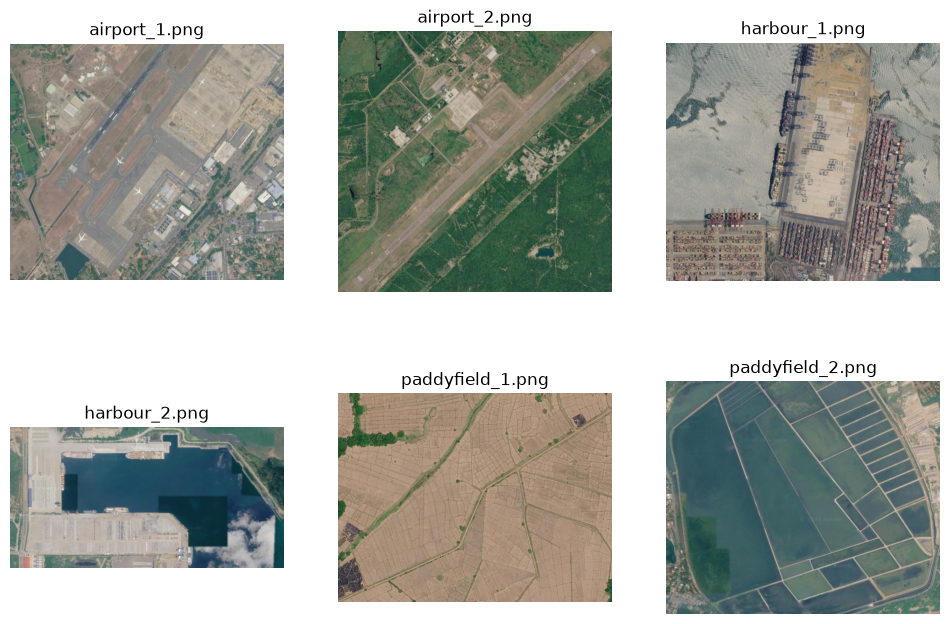

In [2]:
files = sorted(f for f in os.listdir(IMAGE_DIR) if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")))
cols = 3
rows = (len(files) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
axes = axes.flatten() if len(files) > 1 else [axes]
for ax in axes:
    ax.axis("off")
for ax, f in zip(axes, files):
    ax.imshow(Image.open(os.path.join(IMAGE_DIR, f)).convert("RGB"))
    ax.set_title(f)
plt.show()

## 2. Run all models (prompt selection + prediction)

In [3]:
if RUN or not os.path.exists(RESULT):
    r = subprocess.run(
        [sys.executable, "senclip_demo.py", "--image_dir", IMAGE_DIR,
         "--ground_json", GROUND, "--aerial_json", AERIAL, "--topk", str(TOPK)],
        capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:])
        print(r.stderr[-3000:])
    else:
        print("Done. Results saved to", RESULT)
else:
    print("Using the saved results file:", RESULT)


Traceback (most recent call last):
  File "c:\Users\minsa\OneDrive\Desktop\CV\Implementation_senclip\senclip_demo.py", line 247, in <module>
    main()
  File "c:\Users\minsa\OneDrive\Desktop\CV\Implementation_senclip\senclip_demo.py", line 146, in main
    "AERIAL": json.load(open(args.aerial_json, encoding="utf-8"))}
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: 'prompts/my_aerial.json'



## 3. Predicted class for each image (every model, ground and aerial prompts)

In [6]:
import os
print(os.getcwd())
print(os.path.exists("senclip_demo.py"), os.path.exists("my_image"), os.path.exists("prompts/my_ground.json"), os.path.exists("prompts/my_aerial.json"))

c:\Users\minsa\OneDrive\Desktop\CV\Implementation_senclip
True True True True


In [9]:
text = open(RESULT, encoding="utf-8").read()
print(text[text.index("PREDICTIONS PER IMAGE"):])

PREDICTIONS PER IMAGE (class, probability)   [OK/WRONG shown when the file name matches a class]

airport_1.png   (expected from file name: Air Port)
  RN50 AvgPool (official)            ground: Air Port (0.67)  OK | aerial: Air Port (0.66)  OK
  RN50 AttPool (official)            ground: Air Port (0.99)  OK | aerial: Air Port (0.52)  OK
  ViT-B/32 AvgPool (official)        ground: Air Port (1.00)  OK | aerial: Air Port (1.00)  OK
  ViT-B/32 AttPool (official)        ground: Air Port (1.00)  OK | aerial: Air Port (1.00)  OK
  My RN50 AvgPool (trained by me)    ground: Harbour (0.45)  WRONG | aerial: Paddy Field (0.67)  WRONG

airport_2.png   (expected from file name: Air Port)
  RN50 AvgPool (official)            ground: Harbour (0.60)  WRONG | aerial: Harbour (0.52)  WRONG
  RN50 AttPool (official)            ground: Paddy Field (0.92)  WRONG | aerial: Paddy Field (0.98)  WRONG
  ViT-B/32 AvgPool (official)        ground: Air Port (0.99)  OK | aerial: Air Port (1.00)  OK
  ViT-B/32 At

## 4. Selected prompts (ranked by w = alpha / beta)
Pick a model and a view. `show_prompts` prints the top-K prompts of every class.

In [10]:
blocks = text.split("=" * 78)
model_names = [re.search(r"^MODEL: (.*)$", b, re.M).group(1).strip()
               for b in blocks if re.search(r"^MODEL: ", b, re.M)]
print("Models:", model_names)

def show_prompts(model, view="GROUND"):
    for b in blocks:
        m = re.search(r"^MODEL: (.*)$", b, re.M)
        if m and m.group(1).strip() == model:
            if f"[{view} view]" not in b:
                print("This model was skipped (see the results file).")
                return
            part = b.split(f"[{view} view]")[1]
            if view == "GROUND":
                part = part.split("[AERIAL view]")[0]
            print(f"{model} - {view} view" + part)
            return
    print("Model not found. Available:", model_names)

Models: ['RN50 AvgPool (official)', 'RN50 AttPool (official)', 'ViT-B/32 AvgPool (official)', 'ViT-B/32 AttPool (official)', 'My RN50 AvgPool (trained by me)']


In [11]:
show_prompts("RN50 AvgPool (official)", "GROUND")

RN50 AvgPool (official) - GROUND view top-5 prompts per class (highest w first)
    Harbour:
      1. [w=1.208] Fishing boats are moored beside a concrete quay.
      2. [w=1.193] Blue fishing boats are pulled onto a slipway.
      3. [w=1.182] Fishing boats are covered with blue tarpaulins.
      4. [w=1.171] Several empty fishing boats rest at their berths.
      5. [w=1.162] A fishing boat carries brightly coloured floats.
    Air Port:
      1. [w=1.215] An airport de-icing truck stands beside a jet.
      2. [w=1.196] A jet bridge connects the terminal to an airplane.
      3. [w=1.181] A flight information sign hangs outside the terminal.
      4. [w=1.178] Aircraft winglets are visible above the terminal apron.
      5. [w=1.176] An airport fire truck is parked near a hangar.
    Paddy Field:
      1. [w=1.295] A scarecrow stands among growing rice crops.
      2. [w=1.253] A buffalo stands in a muddy rice field.
      3. [w=1.246] Water reflects the sky between rice plants.
   

In [12]:
show_prompts("RN50 AvgPool (official)", "AERIAL")

RN50 AvgPool (official) - AERIAL view top-5 prompts per class (highest w first)
    Harbour:
      1. [w=1.150] An aerial view reveals rows of fishing boats inside a sheltered basin.
      2. [w=1.150] An aerial view shows a naval harbour with patrol vessels arranged along secure docks.
      3. [w=1.147] An aerial view shows several floating docks arranged inside a marina.
      4. [w=1.146] An aerial view shows fishing vessels clustered around a central pier.
      5. [w=1.145] An aerial view shows a large shipyard with vessels positioned inside dry docks.
    Air Port:
      1. [w=1.178] An aerial view shows an airport with a dedicated aircraft de-icing apron.
      2. [w=1.177] An aerial photo shows an airport apron covered with parked passenger aircraft.
      3. [w=1.168] An aerial view reveals a network of taxiways connecting multiple airport terminals.
      4. [w=1.162] An aerial photo shows a large airport with multiple runways and extensive taxiway networks.
      5. [w=1.16

In [13]:
show_prompts("My RN50 AvgPool (trained by me)", "GROUND")

My RN50 AvgPool (trained by me) - GROUND view top-5 prompts per class (highest w first)
    Harbour:
      1. [w=1.208] Fishing boats are moored beside a concrete quay.
      2. [w=1.193] Blue fishing boats are pulled onto a slipway.
      3. [w=1.182] Fishing boats are covered with blue tarpaulins.
      4. [w=1.171] Several empty fishing boats rest at their berths.
      5. [w=1.162] A fishing boat carries brightly coloured floats.
    Air Port:
      1. [w=1.215] An airport de-icing truck stands beside a jet.
      2. [w=1.196] A jet bridge connects the terminal to an airplane.
      3. [w=1.181] A flight information sign hangs outside the terminal.
      4. [w=1.178] Aircraft winglets are visible above the terminal apron.
      5. [w=1.176] An airport fire truck is parked near a hangar.
    Paddy Field:
      1. [w=1.295] A scarecrow stands among growing rice crops.
      2. [w=1.253] A buffalo stands in a muddy rice field.
      3. [w=1.246] Water reflects the sky between rice pla

## Notes
- My images are not Sentinel-2, so predictions can be weaker than on the benchmark data.
- Earlier tests on EuroSAT showed the official checkpoints scoring below the paper's numbers with the released zero-shot script. The prompt ranking uses only the text encoder, so it is not affected.
- With only 6 images, the accuracy is only a rough indication.